# SHL Grammar Scoring Engine

**Objective.** Predict a continuous spoken-grammar score (1–5) for each test audio clip. The competition
scores Pearson correlation and RMSE, and also requires the **training RMSE** to be reported.

**Approach in brief.**
1. Validate the data: files, durations, sample rates, labels.
2. Extract three feature families, each cached: **acoustic** (librosa), **ASR transcripts** (Whisper `small.en`),
   and **linguistic** features (text statistics, spaCy POS/dependency stats, sentence embeddings).
3. Compare simple, regularised models (mean baseline, Ridge, TF-IDF+Ridge, embeddings+Ridge, CatBoost) with
   shuffled 5-fold CV (`random_state=42`). Add a non-negative ensemble whose weights come from training OOF only.
4. Select the model by OOF RMSE, refit it on all labelled data, and write `submission.csv`.

> Every number in this notebook is computed by the cells. The written conclusions at the end describe the run
> recorded in this notebook. If you re-run it with different settings, re-read the generated report cell.

**Where each required report item is covered**

| Required item | Section |
|---|---|
| 1. Approach and dataset | This cell; §2 Dataset overview and validation |
| 2. Audio preprocessing and feature engineering | §3 (with the implementing code) |
| 3. Model pipeline architecture | §4 (diagram plus the implementing code) |
| 4. **Training RMSE (compulsory)** | **§7.1** |
| 5. Cross-validation RMSE and Pearson correlation | §5, §6, §7.2 |
| 6. Visualizations and interpretation | §2 (data), §5 (fold-wise), §7.3 (diagnostics), each followed by an interpretation |
| 7. Final test predictions and `submission.csv` validation | §8 |
| 8. Conclusions and limitations | §9 generated report, §10 |

All code lives in `src/feature_extraction.py` and `src/train.py`. Their docstrings and comments document it,
and §3 and §4 display the source of the key functions inline.

## 1. Configuration

In [1]:
import os, sys, platform, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import Code, Markdown, display
import inspect

warnings.filterwarnings("ignore", category=UserWarning)
# Keep model-loading progress bars and HF warnings out of the report
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")

# Paths are configurable through environment variables (see README).
PROJECT_ROOT = Path(os.environ.get("GSE_PROJECT_ROOT", Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
os.environ.setdefault("GSE_DATA_DIR", str(PROJECT_ROOT / "Dataset_Final"))
os.environ.setdefault("GSE_CACHE_DIR", str(PROJECT_ROOT / "cache"))
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import feature_extraction as fx
import train as T

USE_ASR = os.environ.get("GSE_USE_ASR", "1") == "1"        # set GSE_USE_ASR=0 for an acoustic-only run
SUBMISSION_PATH = PROJECT_ROOT / "submission.csv"
SEED = T.SEED
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})


def show_source(*fns):
    # Display the exact source of functions the notebook calls, read live from src/ so it cannot drift
    for f in fns:
        display(Markdown(f"`{f.__module__}.{f.__name__}`"), Code(inspect.getsource(f), language="python"))


print("Data dir :", fx.DATA_DIR)
print("Cache dir:", fx.CACHE_DIR)
print("USE_ASR  :", USE_ASR)

Data dir : C:\Users\Khushi Sharma\Desktop\proj\Dataset_Final
Cache dir: C:\Users\Khushi Sharma\Desktop\proj\cache
USE_ASR  : True


In [2]:
# Environment report: hardware and optional dependencies
import importlib.util
print("Python", platform.python_version(), "|", platform.platform())
print("CPU threads:", os.cpu_count(), "| free disk (GB):", round(shutil.disk_usage(PROJECT_ROOT).free / 1e9, 1))
try:
    import torch
    print("torch", torch.__version__, "| CUDA GPU available:", torch.cuda.is_available())
except ImportError:
    print("torch not installed (only needed for sentence embeddings)")
for pkg in ["librosa", "sklearn", "catboost", "faster_whisper", "whisper", "sentence_transformers", "spacy"]:
    print(f"  {pkg:22s}", "available" if importlib.util.find_spec(pkg) else "MISSING (optional path skipped)")

Python 3.11.13 | Windows-10-10.0.26200-SP0
CPU threads: 12 | free disk (GB): 365.4


torch 2.14.1+cpu | CUDA GPU available: False
  librosa                available
  sklearn                available
  catboost               available
  faster_whisper         available
  whisper                MISSING (optional path skipped)
  sentence_transformers  available
  spacy                  available


## 2. Dataset overview and validation

In [3]:
train_raw, test, sample = T.load_data()
print("train.csv :", train_raw.shape, list(train_raw.columns))
print("test.csv  :", test.shape, list(test.columns))
print("sample_submission.csv:", sample.shape, list(sample.columns))
print("\nMissing train labels:", int(train_raw["label"].isna().sum()))
print("Duplicate filenames  - train:", int(train_raw["filename"].duplicated().sum()),
      "| test:", int(test["filename"].duplicated().sum()))
print("Test label column values (placeholders):", test["label"].unique())
print("\nTrain label counts:\n", train_raw["label"].value_counts().sort_index().to_string())

train.csv : (769, 2) ['filename', 'label']
test.csv  : (216, 2) ['filename', 'label']
sample_submission.csv: (204, 2) ['filename', 'label']

Missing train labels: 0
Duplicate filenames  - train: 0 | test: 0
Test label column values (placeholders): [-1]

Train label counts:
 label
0.0     37
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133


In [4]:
# Does sample_submission.csv describe the same rows as test.csv?
in_test = sample["filename"].isin(test["filename"])
print(f"sample_submission rows: {len(sample)}; of these, {int(in_test.sum())} are in test.csv")
print(f"test.csv rows: {len(test)}; of these, {int(test['filename'].isin(sample['filename']).sum())} are in sample_submission")
print("Filenames that appear in both train.csv and test.csv:", int(test["filename"].isin(train_raw["filename"]).sum()),
      "(they are in different folders - see the content-hash check below)")

sample_submission rows: 204; of these, 25 are in test.csv
test.csv rows: 216; of these, 25 are in sample_submission
Filenames that appear in both train.csv and test.csv: 212 (they are in different folders - see the content-hash check below)


In [5]:
# Content-hash check: are any train and test clips the same audio despite the folder split?
import hashlib
def md5(p): return hashlib.md5(p.read_bytes()).hexdigest()
h_tr = {md5(fx.audio_path("train", f)): f for f in train_raw["filename"]}
h_te = {md5(fx.audio_path("test", f)): f for f in test["filename"]}
print("Identical audio shared by train and test:", len(set(h_tr) & set(h_te)))
print("Duplicate audio within train:", len(train_raw) - len(h_tr), "| within test:", len(test) - len(h_te))

Identical audio shared by train and test: 0
Duplicate audio within train: 0 | within test: 0


**Findings.**
* `sample_submission.csv` **does not match** `test.csv`: most of its filenames are not test files and have no
  audio in `test/`. We therefore use it **only as the schema template** (column names and order) and take the
  rows and their order from `test.csv`, which lists exactly the 216 audio files we have. If the Kaggle grader
  expects the sample file's IDs, this choice needs to be revisited (see Limitations).
* The overlapping filenames between train and test are per-folder numbering only. The content hashes show no
  shared audio, so there is no train/test leakage.

In [6]:
meta_tr = T.fx.audio_metadata(train_raw, "train").merge(train_raw, on="filename")
meta_te = T.fx.audio_metadata(test, "test")
for name, m in [("train", meta_tr), ("test", meta_te)]:
    print(f"{name}: missing={int((~m['exists']).sum())} unreadable={int(m['error'].notna().sum())} "
          f"sample rates={m['orig_sr'].value_counts().to_dict()} channels={m['channels'].value_counts().to_dict()}")
    print(f"   duration (s): {m['duration_s'].describe().round(2).to_dict()} | total hours = {m['duration_s'].sum()/3600:.2f}")
bad = pd.concat([meta_tr[meta_tr["error"].notna()], meta_te[meta_te["error"].notna()]])
print("\nRecords with audio problems:", "none" if bad.empty else "")
if not bad.empty: display(bad)

train: missing=0 unreadable=0 sample rates={16000: 769} channels={1: 769}
   duration (s): {'count': 769.0, 'mean': 55.78, 'std': 7.91, 'min': 20.06, '25%': 54.19, '50%': 60.07, '75%': 60.07, 'max': 61.04} | total hours = 11.92
test: missing=0 unreadable=0 sample rates={16000: 216} channels={1: 216}
   duration (s): {'count': 216.0, 'mean': 48.76, 'std': 8.18, 'min': 6.48, '25%': 45.06, '50%': 45.06, '75%': 60.01, 'max': 61.03} | total hours = 2.93

Records with audio problems: none


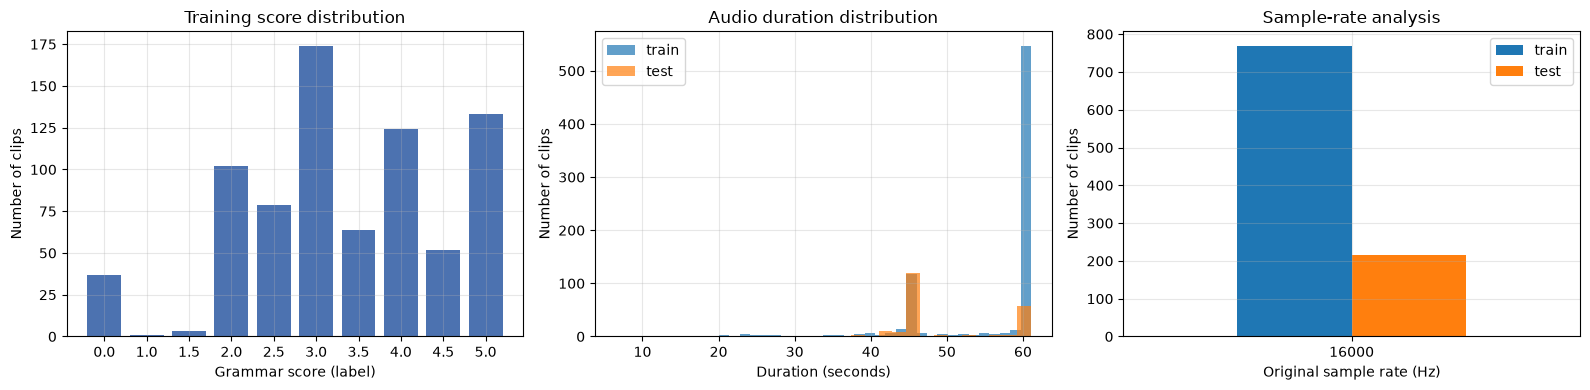

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
vc = train_raw["label"].value_counts().sort_index()
ax[0].bar(vc.index.astype(str), vc.values, color="#4C72B0")
ax[0].set(title="Training score distribution", xlabel="Grammar score (label)", ylabel="Number of clips")
ax[1].hist(meta_tr["duration_s"], bins=30, alpha=0.7, label="train")
ax[1].hist(meta_te["duration_s"], bins=30, alpha=0.7, label="test")
ax[1].set(title="Audio duration distribution", xlabel="Duration (seconds)", ylabel="Number of clips"); ax[1].legend()
sr = pd.concat([meta_tr["orig_sr"].value_counts().rename("train"), meta_te["orig_sr"].value_counts().rename("test")], axis=1).fillna(0)
sr.plot.bar(ax=ax[2], rot=0)
ax[2].set(title="Sample-rate analysis", xlabel="Original sample rate (Hz)", ylabel="Number of clips")
plt.tight_layout(); plt.show()

**Interpretation.**
* **Scores** come in half-point steps. 3.0 is the most common score, and 2.0, 4.0 and 5.0 are also frequent.
  Scores 1.0 and 1.5 together have only 4 clips, so the model can barely learn the bottom of the scale and
  will rarely predict below 2. The 37 clips scored 0.0 lie outside the rubric (§2.1).
* **Durations differ between train and test.** Most training clips are about 60 s long, while most test clips
  are about 45 s. The training set does contain 45 s clips, so this is a shift in proportions and not a new
  regime. §7.4 checks whether it biases the predictions.
* **Sample rate** is a uniform 16 kHz mono for every file, so resampling is a no-op here.

### 2.1 Labels outside the 1–5 rubric
The rubric is 1–5, but the training set contains rows labelled **0.0**. The next cell shows they form a
separate group.

In [8]:
zero = meta_tr[meta_tr["label"] == 0]
idx = meta_tr["filename"].str.extract(r"(\d+)")[0].astype(int)
print("label-0 rows:", len(zero))
print("label-0 rows whose file index is >= 5000:", int((idx[meta_tr["label"] == 0] >= 5000).sum()))
print("non-zero rows whose file index is >= 5000:", int((idx[meta_tr["label"] != 0] >= 5000).sum()))
print("test files whose index is >= 5000:", int((test["filename"].str.extract(r"(\d+)")[0].astype(int) >= 5000).sum()))
print("label-0 durations (s):", zero["duration_s"].describe().round(1).to_dict())

label-0 rows: 37
label-0 rows whose file index is >= 5000: 37
non-zero rows whose file index is >= 5000: 0
test files whose index is >= 5000: 0
label-0 durations (s): {'count': 37.0, 'mean': 57.9, 'std': 7.0, 'min': 24.1, '25%': 60.1, '50%': 60.1, '75%': 60.1, 'max': 61.0}


**Decision.** All label-0 clips (and only those) belong to a separate `audio_5000+` file series. No test file
comes from that series. When transcribed, these clips turn out to be fluent-sounding but semantically
incoherent speech. A score of 0 is outside the 1–5 rubric, so the main model **excludes these rows from
training and validation**. They are reported here, not silently dropped. Section 6.3 runs a sensitivity
check that trains with them included and scores only the 1–5 rows, to show what difference the choice makes.

In [9]:
train, excluded = T.split_out_of_rubric(train_raw)
print(f"Kept for modelling: {len(train)} rows | excluded (label outside 1-5): {len(excluded)} rows")
print("Excluded label counts:", excluded["label"].value_counts().to_dict())
y = train["label"].to_numpy(float)

Kept for modelling: 732 rows | excluded (label outside 1-5): 37 rows
Excluded label counts: {0.0: 37}


## 3. Preprocessing and feature engineering

* **Audio loading.** `librosa.load(..., sr=16000, mono=True)`. Every file is already 16 kHz mono, so no
  resampling is needed. The code still resamples if a different rate ever appears. Unreadable files keep their
  row, with NaN features and an `audio_error` message.
* **Acoustic features (55).** Duration; mean and standard deviation of 13 MFCCs; MFCC-delta magnitude; RMS
  energy; zero-crossing rate; spectral centroid, bandwidth, roll-off and contrast; YIN pitch statistics on
  voiced (energetic) frames; silence ratio; pause count, rate, mean and max (pauses ≥ 300 ms below −35 dB
  relative to the clip's peak); speech time.
* **Transcripts.** `faster-whisper` `small.en` (int8, CPU, beam 5, Silero VAD to skip silences), cached in
  `cache/transcripts_*.json`. We tested an `initial_prompt` meant to preserve fillers and dropped it, because
  Whisper copied the prompt's words into transcripts. `base.en` and greedy decoding were faster but truncated
  some clips to a few words. VAD was faster and kept more of each utterance.
* **Linguistic features.** Word and sentence counts; mean, variance and max sentence length; TTR and root TTR;
  word-length statistics; filler ratio; immediate word repetitions; subordinator ratio; words per minute;
  spaCy POS proportions, clausal-dependency ratio, dependency-tree depth and verbs per sentence.
* **Grammatical acceptability.** `textattack/roberta-base-CoLA`, a RoBERTa model fine-tuned on the Corpus
  of Linguistic Acceptability, scores each transcript sentence. Per clip we keep the mean and min
  P(acceptable) and the fraction of sentences with P < 0.5. This is the feature that targets grammar most
  directly. It still sees only Whisper's normalised text, and CoLA is written English, not speech.
* **Sentence embeddings.** `all-MiniLM-L6-v2` (384-d, normalised), cached.

> **Caveats.** (1) Whisper is trained to output fluent, mostly well-formed text. It often fixes or drops
> disfluencies and some grammatical errors, which shrinks the grammar signal in the transcript. Misrecognitions
> can also *add* errors the speaker never made. (2) Acoustic fluency is **not** grammatical correctness. Acoustic
> features only correlate with proficiency, and the model may lean on them in ways a human rater would not.

**Implementation.** The next cell shows the code that loads audio and computes each feature family, taken
from `src/feature_extraction.py`. Caching, Whisper transcription and sentence embeddings are in the same file.

In [10]:
# Source of the preprocessing / feature-engineering functions used below
show_source(fx.load_audio, fx.acoustic_features, fx.linguistic_features, fx.acceptability_features)

`feature_extraction.load_audio`

def load_audio(path: Path, sr: int = TARGET_SR) -> np.ndarray:
    """Load audio as mono float32, resampled to `sr`. Raises on unreadable files."""
    import librosa

    y, _ = librosa.load(str(path), sr=sr, mono=True)
    if y.size == 0:
        raise ValueError("empty audio")
    return y.astype(np.float32)

`feature_extraction.acoustic_features`

def acoustic_features(y: np.ndarray, sr: int = TARGET_SR) -> dict:
    """Fixed-length acoustic summary of one clip."""
    import librosa

    f = {"duration_s": len(y) / sr}
    hop = 512

    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, hop_length=hop)
    for i in range(mfcc.shape[0]):
        f.update(_stats(f"mfcc{i}", mfcc[i]))
    f.update(_stats("mfcc_delta_abs", np.abs(librosa.feature.delta(mfcc))))

    rms = librosa.feature.rms(y=y, hop_length=hop)[0]
    f.update(_stats("rms", rms))
    f.update(_stats("zcr", librosa.feature.zero_crossing_rate(y, hop_length=hop)[0]))
    f.update(_stats("spec_centroid", librosa.feature.spectral_centroid(y=y, sr=sr, hop_length=hop)[0]))
    f.update(_stats("spec_bandwidth", librosa.feature.spectral_bandwidth(y=y, sr=sr, hop_length=hop)[0]))
    f.update(_stats("spec_rolloff", librosa.feature.spectral_rolloff(y=y, sr=sr, hop_length=hop)[0]))
    contrast = librosa.feature.spectral_contrast(y=y, sr=sr, hop_length=hop)
    for i in range(contrast.shape[0]):
        f[f"spec_contrast{i}_mean"] = float(contrast[i].mean())

    # Pitch (YIN is fast; keep only frames with energy so silence doesn't pollute stats)
    try:
        f0 = librosa.yin(y, fmin=65, fmax=400, sr=sr, hop_length=hop)
        voiced = f0[: len(rms)][rms[: len(f0)] > 0.5 * np.median(rms)]
        f.update(_stats("f0", voiced))
        f["f0_range"] = float(np.ptp(voiced)) if voiced.size else np.nan
    except Exception:
        f.update({"f0_mean": np.nan, "f0_std": np.nan, "f0_range": np.nan})

    # Silence / pause statistics from an energy threshold relative to the clip's own level
    frame_s = hop / sr
    db = librosa.amplitude_to_db(rms, ref=np.max)
    silent = db < -35
    f["silence_ratio"] = float(silent.mean())
    runs, run = [], 0
    for s in silent:
        if s:
            run += 1
        elif run:
            runs.append(run)
            run = 0
    pauses = np.array([r * frame_s for r in runs if r * frame_s >= 0.3])  # internal pauses >= 300 ms
    f["n_pauses"] = int(pauses.size)
    f["pause_rate_per_min"] = pauses.size / max(f["duration_s"] / 60, 1e-6)
    f["mean_pause_s"] = float(pauses.mean()) if pauses.size else 0.0
    f["max_pause_s"] = float(pauses.max()) if pauses.size else 0.0
    f["speech_s"] = float((~silent).sum() * frame_s)
    return f

`feature_extraction.linguistic_features`

def linguistic_features(text: str, duration_s: float | None = None) -> dict:
    text = (text or "").strip()
    words = [w.lower() for w in _WORD.findall(text)]
    n = len(words)
    sents = [s for s in _SENT.split(text) if _WORD.search(s)]
    sent_lens = np.array([len(_WORD.findall(s)) for s in sents]) if sents else np.array([n])
    wl = np.array([len(w) for w in words]) if words else np.array([0])
    cnt = Counter(words)

    f = {
        "empty_transcript": int(n == 0),
        "n_words": n,
        "n_sentences": len(sents),
        "sent_len_mean": float(sent_lens.mean()),
        "sent_len_var": float(sent_lens.var()),
        "sent_len_max": float(sent_lens.max()),
        "ttr": len(cnt) / n if n else 0.0,
        # root TTR is less length-sensitive than plain TTR
        "root_ttr": len(cnt) / np.sqrt(n) if n else 0.0,
        "word_len_mean": float(wl.mean()),
        "word_len_std": float(wl.std()),
        "long_word_ratio": float((wl >= 7).mean()) if n else 0.0,
        "filler_ratio": sum(cnt[w] for w in FILLERS) / n if n else 0.0,
        "immediate_repeats": sum(a == b for a, b in zip(words, words[1:])),
        "subordinator_ratio": sum(cnt[w] for w in SUBORDINATORS) / n if n else 0.0,
        "pronoun_i_ratio": cnt["i"] / n if n else 0.0,
        "comma_per_word": text.count(",") / n if n else 0.0,
    }
    if duration_s and duration_s > 0:
        f["words_per_min"] = n / (duration_s / 60)

    nlp = _spacy()
    if nlp is not None and n:
        doc = nlp(text)
        toks = [t for t in doc if not t.is_punct and not t.is_space]
        pos = Counter(t.pos_ for t in toks)
        tot = max(len(toks), 1)
        for tag in ("NOUN", "VERB", "AUX", "ADJ", "ADV", "PRON", "DET", "ADP", "CCONJ", "SCONJ"):
            f[f"pos_{tag.lower()}"] = pos[tag] / tot
        deps = Counter(t.dep_ for t in toks)
        f["dep_clausal"] = sum(deps[d] for d in ("advcl", "ccomp", "xcomp", "acl", "relcl")) / tot
        depths = []
        for t in toks:
            d = 0
            while t.head.i != t.i and d < 50:  # root's head is itself
                t, d = t.head, d + 1
            depths.append(d)
        f["tree_depth_mean"] = float(np.mean(depths))
        f["verbs_per_sentence"] = (pos["VERB"] + pos["AUX"]) / max(len(list(doc.sents)), 1)
    return f

`feature_extraction.acceptability_features`

def acceptability_features(filenames: list[str], texts: list[str], split: str) -> pd.DataFrame | None:
    """Per-clip stats of sentence-level P(acceptable); cached per filename+text in CACHE_DIR/cola_<split>.json."""
    path = CACHE_DIR / f"cola_{split}.json"
    store = json.loads(path.read_text(encoding="utf-8")) if path.exists() else {}
    keys = [f"{fn}\t{t or ''}" for fn, t in zip(filenames, texts)]
    todo = [i for i, k in enumerate(keys) if k not in store]
    if todo:
        try:
            from transformers import pipeline

            clf = pipeline("text-classification", model=COLA_MODEL, device=-1)
        except Exception as ex:
            print(f"acceptability features disabled ({type(ex).__name__}: {ex})")
            return None
        for i in todo:
            sents = [s.strip() for s in _SENT.split(texts[i] or "") if _WORD.search(s)]
            probs = []
            if sents:
                out = clf(sents, top_k=None, truncation=True, max_length=128, batch_size=16)
                probs = [next(d["score"] for d in o if d["label"] == "LABEL_1") for o in out]
            store[keys[i]] = probs
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        path.write_text(json.dumps(store), encoding="utf-8")

    rows = []
    for k in keys:
        p = np.array(store[k])
        rows.append({"cola_mean": p.mean() if p.size else np.nan, "cola_min": p.min() if p.size else np.nan,
                     "cola_frac_unacceptable": (p < 0.5).mean() if p.size else np.nan})
    return pd.DataFrame(rows)

In [11]:
%%time
# Build every feature block for the 732 modelling rows and the 216 test rows (cached after the first run)
feats = T.build_features(train, test, use_asr=USE_ASR)
ac_err = feats["audio_errors"][0]["audio_error"].notna().sum() + feats["audio_errors"][1]["audio_error"].notna().sum()
print("Acoustic feature matrix:", feats["acoustic"][0].shape, "| audio decode failures:", int(ac_err))
if feats["transcripts"] is not None:
    for name, tx in zip(("train", "test"), feats["transcripts"]):
        print(f"{name}: empty transcripts={int((tx['transcript'].str.strip() == '').sum())}, "
              f"ASR errors={int(tx['asr_error'].notna().sum())}")
    print("Linguistic features:", feats["linguistic"][0].shape[1],
          "| embeddings:", None if feats["embedding"] is None else feats["embedding"][0].shape)
else:
    print("Transcripts unavailable: text-based models are skipped")

Acoustic feature matrix: (732, 55) | audio decode failures: 0
train: empty transcripts=0, ASR errors=0
test: empty transcripts=0, ASR errors=0
Linguistic features: 33 | embeddings: (732, 384)
CPU times: total: 30.8 s
Wall time: 31.8 s


In [12]:
if feats["transcripts"] is not None:
    show = feats["transcripts"][0].assign(label=y)
    for s in (2.0, 3.0, 5.0):
        r = show[show["label"] == s].iloc[0]
        print(f"[label {s}] {r['filename']}: {r['transcript'][:250]}...\n")

[label 2.0] audio_126.wav: Once upon a time, we, with five friends, went on a tour, went on a deep tour with a driver agent on a monologue and we stayed on a resort and we stayed around, we stayed at a resort and after that, we stayed when we checked in, in the resort, after t...

[label 3.0] audio_192.wav: The playground is very, very beautiful and fun. There are playthings like the merry-go-round, the swing. The students usually enjoy the swing. It has to be like, it's more like a game of play. Once the sun is on, the other person will have to push. a...

[label 5.0] audio_592.wav: The journey to Switzerland is an adventure in itself, whether you arrive by plane, train, or car. If you fly into Zurich or Geneva, you'll be greeted by stunning views of Switzerland, as your plane descends towards the airport. From there, you can ta...



## 4. Pipeline architecture and validation strategy

```
WAV ─► librosa (16 kHz mono) ─► acoustic stats ─────────────┐
   └─► Whisper small.en ─► transcript ─► text stats + spaCy ─┤
                                     ├─► RoBERTa-CoLA acceptability ─┼─► [Imputer → StandardScaler → RidgeCV]  ridge_handcrafted
                                     │                       └─► CatBoost (depth 5, 800 iters)          catboost_handcrafted
                                     ├─► TF-IDF (1–2 grams) ─► RidgeCV                                  tfidf_ridge
                                     └─► MiniLM embeddings ─► Scaler → RidgeCV                          embedding_ridge
                                                         (+ handcrafted)                                ridge_emb+handcrafted
OOF predictions of all candidates ─► non-negative least squares (weights sum to 1) ─► ensemble
```

* **Validation.** `KFold(n_splits=5, shuffle=True, random_state=42)`. The label distribution is fairly smooth
  across 2–5, so plain shuffled K-fold is enough.
* **No leakage.** Every learned transform (imputer, scaler, TF-IDF vocabulary, Ridge α chosen by `RidgeCV`'s
  internal efficient LOO) sits inside an sklearn `Pipeline` and is refit on each training fold. ASR, the spaCy
  parser and the embedding model are pretrained and frozen, and they never see labels.
* **Ensemble weights.** NNLS on OOF predictions. To get an honest estimate, the ensemble's OOF score uses
  *nested* weights: fold *k* is scored with weights fit only on the other four folds' OOF rows. The final
  weights are fit on all training OOF rows. No test information is used anywhere.
* **Selection bias.** We choose among a handful of candidates using the same folds, which makes the winner's
  score slightly optimistic. Section 6.2 re-runs the whole comparison on an independent split (seed 2024) to
  check that the ranking holds.
* **Clipping.** Every prediction (OOF, in-sample and test) is clipped to the rubric range [1, 5] exactly as in
  the submission, so training and validation metrics describe the predictions that are actually submitted.

**Implementation** (from `src/train.py`): candidate models, cross-validation, the nested ensemble and the final refit.

In [13]:
show_source(T.candidate_models, T.cross_validate, T.ensemble_weights, T.nested_ensemble_oof, T.fit_predict)

`train.candidate_models`

def candidate_models(feats: dict) -> dict:
    """name -> (X_train, X_test, estimator). Only models whose inputs exist are returned."""
    ac_tr, ac_te = feats["acoustic"]
    m = {"ridge_acoustic": (ac_tr, ac_te, _tabular_ridge())}
    gbm_name, gbm = _gbm()

    if feats["linguistic"] is None:
        m[f"{gbm_name}_acoustic"] = (ac_tr, ac_te, gbm)
        return m

    li_tr, li_te = feats["linguistic"]
    hc_tr, hc_te = _hstack(ac_tr, li_tr), _hstack(ac_te, li_te)
    m["ridge_handcrafted"] = (hc_tr, hc_te, _tabular_ridge())
    m[f"{gbm_name}_handcrafted"] = (hc_tr, hc_te, gbm)

    tx_tr, tx_te = feats["text"]
    tfidf = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("ridge", RidgeCV(alphas=ALPHAS)),
    ])
    m["tfidf_ridge"] = (tx_tr, tx_te, tfidf)

    if feats["embedding"] is not None:
        e_tr, e_te = feats["embedding"]
        m["embedding_ridge"] = (e_tr, e_te, make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS)))
        # embeddings + handcrafted in one regularised linear model
        cols_e = [f"emb{i}" for i in range(e_tr.shape[1])]
        eh_tr = _hstack(hc_tr, pd.DataFrame(e_tr, columns=cols_e))
        eh_te = _hstack(hc_te, pd.DataFrame(e_te, columns=cols_e))
        prep = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
                                   list(eh_tr.columns))])
        m["ridge_emb+handcrafted"] = (eh_tr, eh_te, make_pipeline(prep, RidgeCV(alphas=ALPHAS)))
    return m

`train.cross_validate`

def cross_validate(X, y: np.ndarray, est, folds) -> tuple[np.ndarray, pd.DataFrame]:
    """Out-of-fold predictions + per-fold RMSE / Pearson.

    Predictions are clipped to SCORE_RANGE exactly as the submission is, so validation
    metrics describe the predictions we actually submit.
    """
    oof = np.full(len(y), np.nan)
    rows = []
    for k, (tr, va) in enumerate(folds):
        model = clone(est).fit(_take(X, tr), y[tr])
        oof[va] = np.clip(model.predict(_take(X, va)), *SCORE_RANGE)
        rows.append({"fold": k + 1, "rmse": rmse(y[va], oof[va]), "pearson": pearson(y[va], oof[va])})
    return oof, pd.DataFrame(rows)

`train.ensemble_weights`

def ensemble_weights(P: np.ndarray, y: np.ndarray) -> np.ndarray:
    """Non-negative least-squares weights on OOF predictions, normalised to sum to 1."""
    w, _ = nnls(P, y)
    return w / w.sum() if w.sum() > 0 else np.full(P.shape[1], 1 / P.shape[1])

`train.nested_ensemble_oof`

def nested_ensemble_oof(P: np.ndarray, y: np.ndarray, folds) -> tuple[np.ndarray, pd.DataFrame]:
    """Honest ensemble estimate: fold k's weights come only from the OOF rows of the other folds."""
    oof = np.full(len(y), np.nan)
    rows = []
    for k, (tr, va) in enumerate(folds):
        w = ensemble_weights(P[tr], y[tr])
        oof[va] = np.clip(P[va] @ w, *SCORE_RANGE)
        rows.append({"fold": k + 1, "rmse": rmse(y[va], oof[va]), "pearson": pearson(y[va], oof[va])})
    return oof, pd.DataFrame(rows)

`train.fit_predict`

def fit_predict(selected: str, models: dict, cv: dict, y: np.ndarray):
    """Refit the selected model (or every ensemble member) on all training data.

    Returns (train_pred_in_sample, test_pred, ensemble_weights_or_None), both clipped to
    SCORE_RANGE like the OOF predictions, so training and validation metrics are comparable.
    """
    tr_pred, te_pred, w = _fit_predict_raw(selected, models, cv, y)
    clip = lambda p: None if p is None else np.clip(p, *SCORE_RANGE)
    return clip(tr_pred), clip(te_pred), w

## 5. Model comparison (5-fold OOF)

In [14]:
%%time
models = T.candidate_models(feats)
folds = T.make_folds(len(y), seed=SEED)
cv = T.run_cv(models, y, folds)
cv["table"].round(4)

CV: ridge_acoustic
CV: ridge_handcrafted


CV: catboost_handcrafted


CV: tfidf_ridge


CV: embedding_ridge


CV: ridge_emb+handcrafted


CPU times: total: 3min 16s
Wall time: 22.1 s


,model,oof_rmse,oof_pearson,fold_rmse_mean,fold_rmse_std,fold_pearson_mean,fold_pearson_std
0,ensemble,0.6408,0.7837,0.6403,0.0299,0.7841,0.0267
1,catboost_handcrafted,0.6692,0.7522,0.6688,0.0252,0.7530,0.0288
2,ridge_emb+handcrafted,0.6744,0.7470,0.6737,0.0343,0.7471,0.0363
3,ridge_handcrafted,0.6913,0.7315,0.6912,0.0163,0.7338,0.0278
4,embedding_ridge,0.7728,0.6475,0.7720,0.0409,0.6458,0.0539
5,tfidf_ridge,0.7994,0.6185,0.7993,0.0138,0.6230,0.0409
6,ridge_acoustic,0.8387,0.5617,0.8379,0.0414,0.5601,0.0563
7,mean_baseline,1.0155,NaN,1.0146,0.0470,NaN,NaN


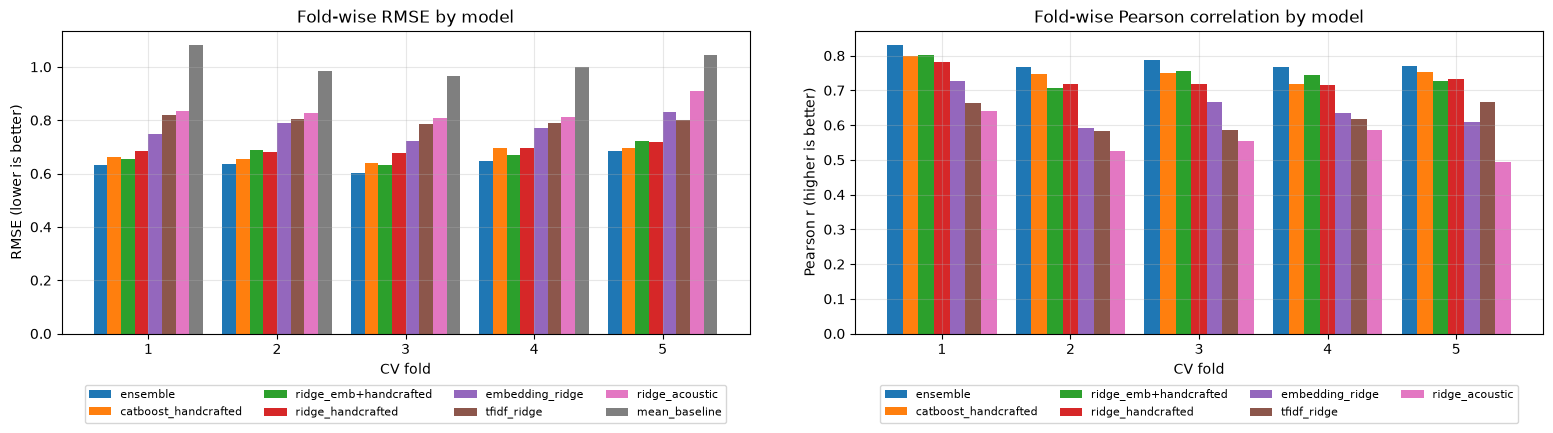

model,ensemble,catboost_handcrafted,ridge_emb+handcrafted,ridge_handcrafted,embedding_ridge,tfidf_ridge,ridge_acoustic,mean_baseline
fold,,,,,,,,
1,0.6323,0.6607,0.6560,0.6831,0.7478,0.8199,0.8349,1.0807
2,0.6357,0.6546,0.6901,0.6809,0.7887,0.8036,0.8272,0.9829
3,0.6020,0.6389,0.6320,0.6775,0.7216,0.7853,0.8071,0.9664
4,0.6463,0.6952,0.6683,0.6974,0.7724,0.7882,0.8113,0.9984
5,0.6850,0.6947,0.7221,0.7169,0.8294,0.7994,0.9092,1.0444


In [15]:
fm = pd.concat([d.assign(model=n) for n, d in cv["folds"].items()])
order = cv["table"]["model"].tolist()
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for metric, a in zip(("rmse", "pearson"), ax):
    pv = fm.pivot(index="fold", columns="model", values=metric)[order]
    if metric == "pearson": pv = pv.drop(columns="mean_baseline")
    pv.plot.bar(ax=a, rot=0, width=0.85)
    a.set(title=f"Fold-wise {'RMSE' if metric=='rmse' else 'Pearson correlation'} by model",
          xlabel="CV fold", ylabel="RMSE (lower is better)" if metric == "rmse" else "Pearson r (higher is better)")
    a.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.tight_layout(); plt.show()
fm.pivot(index="fold", columns="model", values="rmse")[order].round(4)

**Interpretation.**
* Every model beats the mean baseline (OOF RMSE 1.016) by a wide margin. The **ensemble has the lowest RMSE
  in all five folds**, so its lead is not driven by one lucky fold.
* **Transcript-based features carry most of the signal.** Acoustic-only Ridge reaches RMSE 0.839. Adding the
  linguistic, spaCy and CoLA features (`ridge_handcrafted`) lowers it to 0.691, and CatBoost on the same
  features lowers it further to 0.669.
* TF-IDF (0.799) and embeddings alone (0.773) are weaker on their own. Combined with the handcrafted features
  (0.674) or in the ensemble, they add complementary information.
* Fold-to-fold RMSE standard deviations range from 0.014 to 0.041 across the models. Gaps smaller than that, such as CatBoost vs
  Ridge emb+handcrafted at 0.669 vs 0.674, are within noise.

## 6. Model selection

In [16]:
SELECTED = cv["table"].iloc[0]["model"]
print("Selected by lowest 5-fold OOF RMSE:", SELECTED)
cv["folds"][SELECTED].round(4)

Selected by lowest 5-fold OOF RMSE: ensemble


,fold,rmse,pearson
0,1,0.6323,0.8296
1,2,0.6357,0.7661
2,3,0.6020,0.7864
3,4,0.6463,0.7673
4,5,0.6850,0.7712


### 6.2 Robustness: the same comparison on an independent fold split (seed 2024)

In [17]:
%%time
cv_alt = T.run_cv(models, y, T.make_folds(len(y), seed=2024))
cmp = cv["table"][["model", "oof_rmse", "oof_pearson"]].merge(
    cv_alt["table"][["model", "oof_rmse", "oof_pearson"]], on="model", suffixes=("_seed42", "_seed2024"))
print("Winner on seed-2024 split:", cv_alt["table"].iloc[0]["model"])
cmp.round(4)

CV: ridge_acoustic
CV: ridge_handcrafted


CV: catboost_handcrafted


CV: tfidf_ridge


CV: embedding_ridge


CV: ridge_emb+handcrafted


Winner on seed-2024 split: ensemble
CPU times: total: 3min 15s
Wall time: 21 s


,model,oof_rmse_seed42,oof_pearson_seed42,oof_rmse_seed2024,oof_pearson_seed2024
0,ensemble,0.6408,0.7837,0.6437,0.7800
1,catboost_handcrafted,0.6692,0.7522,0.6691,0.7523
2,ridge_emb+handcrafted,0.6744,0.7470,0.6782,0.7432
3,ridge_handcrafted,0.6913,0.7315,0.7065,0.7179
4,embedding_ridge,0.7728,0.6475,0.7720,0.6481
5,tfidf_ridge,0.7994,0.6185,0.7898,0.6334
6,ridge_acoustic,0.8387,0.5617,0.8515,0.5431
7,mean_baseline,1.0155,NaN,1.0146,NaN


### 6.3 Sensitivity: what if the 37 label-0 rows are kept in training?

In [18]:
%%time
# Train on all 769 rows; evaluate only the 1-5 rows so the scores are comparable with the main run.
best_single = next(m for m in cv["table"]["model"] if m in models)
y_all = train_raw["label"].to_numpy(float)
feats_all = T.build_features(train_raw, test, use_asr=USE_ASR)   # cached, so this is fast
Xa, _, est = T.candidate_models(feats_all)[best_single]
oof_all, _ = T.cross_validate(Xa, y_all, est, T.make_folds(len(y_all), seed=SEED))
mask = train_raw["label"].between(*T.SCORE_RANGE).to_numpy()
oof_all_c = np.clip(oof_all, *T.SCORE_RANGE)
row = cv["table"].set_index("model").loc[best_single]
print(f"{best_single}: zeros excluded   -> OOF RMSE {row.oof_rmse:.4f}, r {row.oof_pearson:.4f} (1-5 rows)")
print(f"{best_single}: zeros in training -> OOF RMSE {T.rmse(y_all[mask], oof_all_c[mask]):.4f}, "
      f"r {T.pearson(y_all[mask], oof_all_c[mask]):.4f} (1-5 rows, clipped)")
if feats_all["transcripts"] is not None:   # evidence for the "incoherent speech" observation in 2.1
    tx0 = feats_all["transcripts"][0][~mask]
    for _, r in tx0.head(3).iterrows():
        print(f"\n[label 0] {r['filename']}: {r['transcript'][:220]}...")

catboost_handcrafted: zeros excluded   -> OOF RMSE 0.6692, r 0.7522 (1-5 rows)
catboost_handcrafted: zeros in training -> OOF RMSE 0.6836, r 0.7388 (1-5 rows, clipped)

[label 0] audio_5055.wav: More incredibly, the wind is off on my skin, which is why I start to feel so daily. Every time I leave my cough, I can make myself forget my face, or whatever it is I need to add up there, but just flatten my heart, So t...

[label 0] audio_5066.wav: This, the best thing about life more than a potato, or than a rhythm, is that you can use both the three wheels. It's a wonder for you don't do that, because you are moving at the same point, but you don't walk through e...

[label 0] audio_5069.wav: This is the first time that I have ever seen a black person in the city. But I've never done it in the city since I was a teenager. The news I've never done it before and I've never seen it before. I don't remember any o...
CPU times: total: 3min 41s
Wall time: 46.5 s


## 7. Final model: training RMSE and cross-validation metrics

### 7.1 Training RMSE (compulsory)
The selected model is refit on **all 732 labelled training rows** and then predicts **those same rows**. The
RMSE of these in-sample predictions is the competition's required *training RMSE*.

In [19]:
# Refit on all labelled data -> in-sample train predictions + test predictions (both clipped to [1, 5])
train_pred, test_pred, weights = T.fit_predict(SELECTED, models, cv, y)
TRAIN_RMSE = T.rmse(y, train_pred)
print("Selected model:", SELECTED)
if weights: print("Ensemble weights (fit on training OOF only):", {k: round(v, 3) for k, v in weights.items()})
display(Markdown(f"### Training RMSE (in-sample) = **{TRAIN_RMSE:.4f}**  \n"
                 f"Training Pearson (in-sample) = {T.pearson(y, train_pred):.4f}, on n = {len(y)} rows"))

Selected model: ensemble
Ensemble weights (fit on training OOF only): {'ridge_acoustic': 0.0, 'ridge_handcrafted': 0.012, 'catboost_handcrafted': 0.492, 'tfidf_ridge': 0.07, 'embedding_ridge': 0.0, 'ridge_emb+handcrafted': 0.426}


### Training RMSE (in-sample) = **0.3232**  
Training Pearson (in-sample) = 0.9595, on n = 732 rows

The training RMSE is **not** a validation score. The model has already seen these rows, so the number is
optimistic and only shows how closely it fits its training data. The validation estimate is the
out-of-fold (OOF) RMSE in §7.2. OOF predictions are not test predictions.

### 7.2 Cross-validation metrics of the selected model

In [20]:
oof = cv["oof"][SELECTED]   # each row predicted by a model that never saw it (5-fold, seed 42)
summary = pd.DataFrame([
    {"metric": "Training RMSE (in-sample: refit on all train, predicted on the same rows)", "value": TRAIN_RMSE},
    {"metric": "5-fold OOF RMSE (validation)", "value": T.rmse(y, oof)},
    {"metric": "5-fold OOF Pearson (validation)", "value": T.pearson(y, oof)},
    {"metric": "Fold RMSE mean ± std", "value": f"{cv['folds'][SELECTED]['rmse'].mean():.4f} ± {cv['folds'][SELECTED]['rmse'].std(ddof=1):.4f}"},
    {"metric": "Fold Pearson mean ± std", "value": f"{cv['folds'][SELECTED]['pearson'].mean():.4f} ± {cv['folds'][SELECTED]['pearson'].std(ddof=1):.4f}"},
    {"metric": "Seed-2024 split: OOF RMSE / Pearson",
     "value": "{:.4f} / {:.4f}".format(*cv_alt["table"].set_index("model").loc[SELECTED, ["oof_rmse", "oof_pearson"]])},
    {"metric": "Mean-baseline OOF RMSE", "value": cv["table"].set_index("model").loc["mean_baseline", "oof_rmse"]},
])
summary

,metric,value
0,"Training RMSE (in-sample: refit on all train, ...",0.323165
1,5-fold OOF RMSE (validation),0.640797
2,5-fold OOF Pearson (validation),0.783685
3,Fold RMSE mean ± std,0.6403 ± 0.0299
4,Fold Pearson mean ± std,0.7841 ± 0.0267
5,Seed-2024 split: OOF RMSE / Pearson,0.6437 / 0.7800
6,Mean-baseline OOF RMSE,1.015491


### 7.3 Diagnostic visualizations

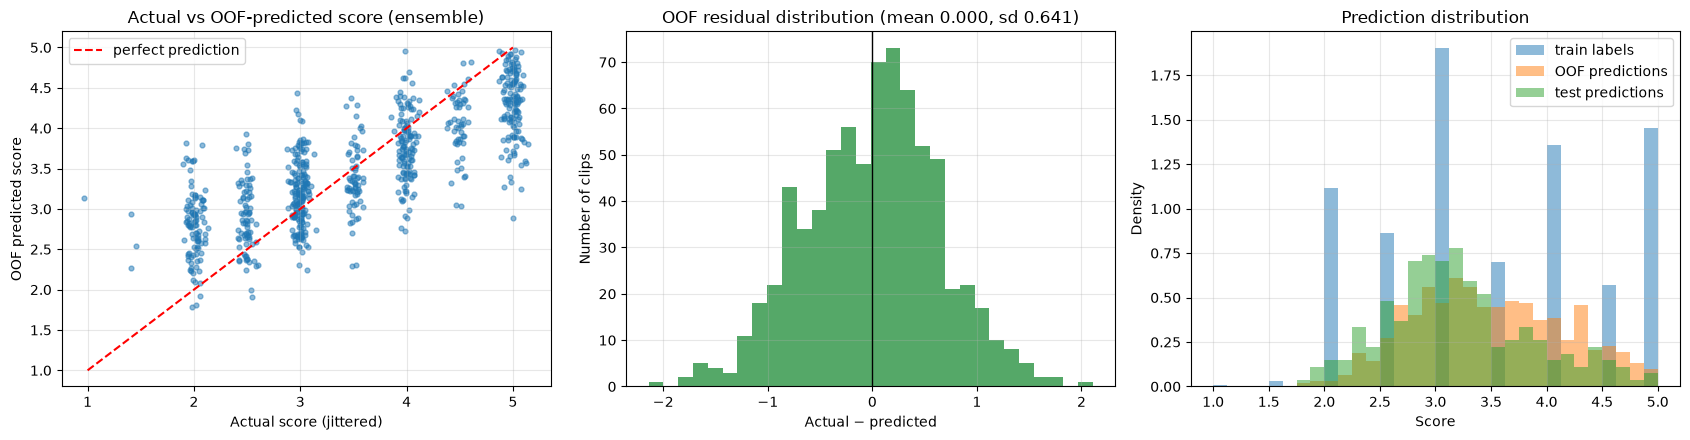

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
jit = np.random.default_rng(SEED).normal(0, 0.05, len(y))
ax[0].scatter(y + jit, oof, s=12, alpha=0.5)
ax[0].plot([1, 5], [1, 5], "r--", label="perfect prediction"); ax[0].legend()
ax[0].set(title=f"Actual vs OOF-predicted score ({SELECTED})", xlabel="Actual score (jittered)", ylabel="OOF predicted score")
res = y - oof
ax[1].hist(res, bins=30, color="#55A868")
ax[1].axvline(0, color="k", lw=1)
ax[1].set(title=f"OOF residual distribution (mean {res.mean():.3f}, sd {res.std():.3f})", xlabel="Actual − predicted", ylabel="Number of clips")
bins = np.linspace(1, 5, 33)
ax[2].hist(y, bins=bins, alpha=0.5, label="train labels", density=True)
ax[2].hist(oof, bins=bins, alpha=0.5, label="OOF predictions", density=True)
ax[2].hist(test_pred, bins=bins, alpha=0.5, label="test predictions", density=True)
ax[2].set(title="Prediction distribution", xlabel="Score", ylabel="Density"); ax[2].legend()
plt.tight_layout(); plt.show()

**Interpretation.**
* **Actual vs OOF.** Predictions rise steadily with the true score (OOF Pearson 0.784). The cloud is flatter
  than the diagonal: clips scored 2 are mostly predicted around 2.5–3.5, and many clips scored 5 are predicted
  around 4–4.5. This is regression to the mean, caused by regularisation and by the noisy, discrete labels.
* **Residuals** are centred on zero (mean 0.000, sd 0.641) and roughly symmetric, so there is no overall
  bias. The tails reach about ±2 points.
* **Prediction distribution.** OOF and test predictions are continuous and narrower than the labels, as the
  shrinkage implies. Test predictions sit lower than OOF predictions, with more mass around 2.5–3.3. §7.4
  shows this matches the test set's larger share of 45 s clips, which score lower in the training data too.

### 7.4 Check: does the train/test clip-length difference bias the predictions?
Most training clips are about 60 s long and most test clips about 45 s (§2). Several features are absolute
counts that grow with clip length, such as duration, word count and pause count. If the model learned
"longer means better", every 45 s test clip would be under-predicted. The check groups OOF residuals and test
predictions by clip length.

In [22]:
dur_tr = feats["acoustic"][0]["duration_s"].to_numpy()
dur_te = feats["acoustic"][1]["duration_s"].to_numpy()
bucket = lambda d: pd.cut(d, [0, 40, 50, 58, 99], labels=["<40 s", "40-50 s", "50-58 s", ">=58 s"])
pd.DataFrame({
    "train clips": pd.Series(y).groupby(bucket(dur_tr), observed=False).size(),
    "train label mean": pd.Series(y).groupby(bucket(dur_tr), observed=False).mean(),
    "OOF pred mean": pd.Series(oof).groupby(bucket(dur_tr), observed=False).mean(),
    "OOF residual mean (y - pred)": pd.Series(y - oof).groupby(bucket(dur_tr), observed=False).mean(),
    "test clips": pd.Series(test_pred).groupby(bucket(dur_te), observed=False).size(),
    "test pred mean": pd.Series(test_pred).groupby(bucket(dur_te), observed=False).mean(),
}).round(3)

,train clips,train label mean,OOF pred mean,OOF residual mean (y - pred),test clips,test pred mean
<40 s,29,3.500,3.358,0.142,8,3.055
40-50 s,149,3.060,3.160,-0.100,141,3.017
50-58 s,27,3.759,3.771,-0.012,8,3.360
>=58 s,527,3.584,3.563,0.021,59,3.647


**Interpretation.** Clip length is associated with the score in the training labels themselves: 40–50 s clips
have a mean label of 3.06, against 3.58 for ≥58 s clips, which probably reflects different prompts or tasks.
The model reproduces this without systematic bias. The OOF residual mean is −0.10 for 40–50 s clips and
+0.02 for ≥58 s clips, small next to the 0.64 RMSE. For the 141 test clips of 40–50 s, the mean prediction is
3.02, close to that group's training label mean of 3.06. The lower average test prediction (3.20) is
therefore explained by the test set's composition and is not an artefact of length. In a separate experiment
we removed the length-dependent count features (duration, speech time, pauses, words, sentences, repeats).
OOF RMSE got slightly worse (0.644 vs 0.641, measured before OOF clipping was introduced), so the features
were kept.

## 8. Final test predictions and `submission.csv` validation
The submission takes its column names and order from `sample_submission.csv`, and its rows and their order
from `test.csv` (see §2 for why). Predictions are continuous; they are clipped to [1, 5] and not rounded.

In [23]:
sub = T.write_submission(test, sample, test_pred, SUBMISSION_PATH, clip=T.SCORE_RANGE)

# Re-read the file from disk and validate what will actually be uploaded
saved = pd.read_csv(SUBMISSION_PATH)
report = T.validate_submission(saved, test, sample, T.SCORE_RANGE)
print("Saved:", SUBMISSION_PATH.resolve())
for k, v in report.items(): print(f"  {k:28s} {v}")
assert len(saved) == 216, f"expected 216 prediction rows, got {len(saved)}"
assert list(saved.columns) == list(sample.columns), "columns differ from sample_submission.csv"
assert report["ok"], "submission validation failed"
print(f"\nOK: {len(saved)} rows, columns {list(saved.columns)} match sample_submission.csv")
print("Test prediction summary:", saved["label"].describe().round(3).to_dict())
saved.head()

Saved: C:\Users\Khushi Sharma\Desktop\proj\submission.csv
  columns_match_sample         True
  rows                         216
  expected_rows(test.csv)      216
  row_order_matches_test       True
  unique_ids                   True
  missing_or_inf               0
  min                          1.868176978675208
  max                          5.0
  within_range                 True
  sample_rows                  204
  sample_ids_in_test           25
  ok                           True

OK: 216 rows, columns ['filename', 'label'] match sample_submission.csv
Test prediction summary: {'count': 216.0, 'mean': 3.203, 'std': 0.66, 'min': 1.868, '25%': 2.785, '50%': 3.125, '75%': 3.561, 'max': 5.0}


,filename,label
0,audio_128.wav,3.001717
1,audio_156.wav,3.902722
2,audio_19.wav,4.239862
3,audio_108.wav,2.359376
4,audio_206.wav,2.729140


## 9. Generated results report (all values computed above)

In [24]:
from IPython.display import Markdown
t = cv["table"].copy()
lines = ["| Model | OOF RMSE | OOF Pearson | Fold RMSE (mean ± sd) | Fold r (mean ± sd) |", "|---|---|---|---|---|"]
for _, r in t.iterrows():
    lines.append(f"| {r.model}{' **(selected)**' if r.model == SELECTED else ''} | {r.oof_rmse:.4f} | {r.oof_pearson:.4f} | "
                 f"{r.fold_rmse_mean:.4f} ± {r.fold_rmse_std:.4f} | {r.fold_pearson_mean:.4f} ± {r.fold_pearson_std:.4f} |")
Markdown(f'''
**Run settings:** ASR={'on (' + os.environ.get('GSE_WHISPER_MODEL', 'small.en') + ')' if feats['transcripts'] is not None else 'off'}, rows used={len(y)} (excluded {len(excluded)} out-of-rubric), 5-fold KFold seed {SEED}.

**Selected model:** `{SELECTED}`{'  — weights: ' + ', '.join(f'{k} {v:.2f}' for k, v in weights.items()) if weights else ''}

| Metric | Value |
|---|---|
| **Training RMSE (in-sample)** | **{TRAIN_RMSE:.4f}** |
| 5-fold OOF RMSE | {T.rmse(y, oof):.4f} |
| 5-fold OOF Pearson | {T.pearson(y, oof):.4f} |
| Mean-baseline OOF RMSE | {t.set_index('model').loc['mean_baseline', 'oof_rmse']:.4f} |

{chr(10).join(lines)}

Submission: `{SUBMISSION_PATH.name}`, {len(sub)} rows, validation ok = {report['ok']}.
''')


**Run settings:** ASR=on (small.en), rows used=732 (excluded 37 out-of-rubric), 5-fold KFold seed 42.

**Selected model:** `ensemble`  — weights: ridge_acoustic 0.00, ridge_handcrafted 0.01, catboost_handcrafted 0.49, tfidf_ridge 0.07, embedding_ridge 0.00, ridge_emb+handcrafted 0.43

| Metric | Value |
|---|---|
| **Training RMSE (in-sample)** | **0.3232** |
| 5-fold OOF RMSE | 0.6408 |
| 5-fold OOF Pearson | 0.7837 |
| Mean-baseline OOF RMSE | 1.0155 |

| Model | OOF RMSE | OOF Pearson | Fold RMSE (mean ± sd) | Fold r (mean ± sd) |
|---|---|---|---|---|
| ensemble **(selected)** | 0.6408 | 0.7837 | 0.6403 ± 0.0299 | 0.7841 ± 0.0267 |
| catboost_handcrafted | 0.6692 | 0.7522 | 0.6688 ± 0.0252 | 0.7530 ± 0.0288 |
| ridge_emb+handcrafted | 0.6744 | 0.7470 | 0.6737 ± 0.0343 | 0.7471 ± 0.0363 |
| ridge_handcrafted | 0.6913 | 0.7315 | 0.6912 ± 0.0163 | 0.7338 ± 0.0278 |
| embedding_ridge | 0.7728 | 0.6475 | 0.7720 ± 0.0409 | 0.6458 ± 0.0539 |
| tfidf_ridge | 0.7994 | 0.6185 | 0.7993 ± 0.0138 | 0.6230 ± 0.0409 |
| ridge_acoustic | 0.8387 | 0.5617 | 0.8379 ± 0.0414 | 0.5601 ± 0.0563 |
| mean_baseline | 1.0155 | nan | 1.0146 ± 0.0470 | nan ± nan |

Submission: `submission.csv`, 216 rows, validation ok = True.


## 10. Limitations and conclusions

**Limitations**
* **ASR as a filter.** Grammar is judged from Whisper's transcript, and Whisper tends to normalise toward
  fluent, well-formed English. Some real errors disappear and some recognition errors appear. A
  disfluency-preserving ASR, or modelling the audio directly with a speech encoder, could keep more signal.
* **Proxy features.** The handcrafted linguistic features (POS mix, clause depth, sentence length) measure
  complexity rather than correctness. Acoustic features capture fluency and recording conditions, which are
  not grammar. The model uses whatever correlates with the labels in this dataset.
* **Small data.** About 730 usable labels give fold-to-fold metric spreads of a few hundredths. Differences
  between models smaller than the fold standard deviation should not be over-interpreted.
* **Data quirks.** 37 out-of-rubric label-0 rows were excluded (section 2.1, sensitivity check in 6.3).
  `sample_submission.csv` does not match `test.csv`, so the submission takes its rows from `test.csv`. Confirm
  which ID set the grader expects before submitting.
* **Selection on the same folds** slightly flatters the chosen model. The seed-2024 re-run (6.2) is the check.
* **Shrinkage toward the mean.** As §7.3 shows, predictions are compressed: 2s are over-predicted and 5s
  under-predicted. This is typical for regularised regression on noisy labels, and it costs RMSE at the
  extremes.
* **No leaderboard check.** All metrics here come from training data via cross-validation. The test score is
  unknown until the submission is uploaded.

**Conclusions** (run recorded in this notebook: Whisper `small.en` with beam 5 and VAD, 732 rows, 5-fold KFold
seed 42; §9 holds the computed numbers).
1. **Approach.** A pretrained-feature pipeline (ASR transcripts, linguistic statistics, CoLA grammaticality
   scores, sentence embeddings and acoustic statistics) feeds small, regularised models. This works far better
   on 732 labels than training a network from scratch.
2. **Training RMSE (in-sample) = 0.323.** This is the compulsory metric. It reflects how well the model fits
   its training data and is *not* a performance estimate.
3. **Cross-validation:** OOF RMSE **0.641**, Pearson **0.784**, with fold RMSE 0.640 ± 0.030. The mean
   baseline scores RMSE 1.016. On an independent seed-2024 split the same model scores 0.644 / 0.780 and still
   ranks first.
4. **Selected model: NNLS ensemble.** Its weights are about 0.49 CatBoost-handcrafted, 0.43 Ridge on
   embeddings + handcrafted, 0.07 TF-IDF and 0.01 Ridge-handcrafted, all fit on training OOF predictions only.
5. **Data decisions were checked, not assumed.** Excluding the 37 out-of-rubric label-0 rows improved the best
   single model on the 1–5 rows (OOF RMSE 0.669 vs 0.684). The train/test clip-length shift was examined and
   does not bias the predictions (§7.4).
6. **Submission.** `submission.csv` has 216 rows in `test.csv` order, the columns `filename,label` from
   `sample_submission.csv`, no missing or infinite values, and every value in [1, 5].